# 07. Análisis de monitoreo, negocio y gobernanza — OralSolutions
Análisis de los ocho lotes evaluados de SIM_2025_V1. Se consultan Snowflake y MLflow sin repetir entrenamiento ni inferencia. Los resultados corresponden a datos sintéticos y no prueban efectividad clínica.

In [1]:
import os, sys
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src'/'datos.py').exists())
sys.path.insert(0, str(ROOT))
from src.datos import conectar_snowflake, consultar_dataframe
from dotenv import load_dotenv
load_dotenv(ROOT/'.env')
SCHEMA = 'ORALSOLUTIONS_DW.MLOPS'
SIM = 'SIM_2025_V1'
FILTRO = f"SIMULACION_ID = '{SIM}' AND LOTE_ID BETWEEN 'L01' AND 'L08'"
DOCS = ROOT/'docs'
DOCS.mkdir(exist_ok=True)
def consulta(sql):
    conn = conectar_snowflake()
    try:
        return consultar_dataframe(conn, sql)
    finally:
        conn.close()
def tabla(nombre):
    return consulta(f'SELECT * FROM {SCHEMA}.{nombre} WHERE {FILTRO} ORDER BY LOTE_ID')

import matplotlib.pyplot as plt
import mlflow
from mlflow.tracking import MlflowClient
from sklearn.metrics import average_precision_score
mon = tabla('MONITOREO')
inm = tabla('MONITOREO_INMEDIATO')
deriva = tabla('DERIVA_FEATURES')
alertas = tabla('ALERTAS')
assert len(mon)==len(inm)==8 and mon.lote_id.is_unique and inm.lote_id.is_unique
assert len(deriva)==104 and not deriva.duplicated(['lote_id','feature']).any()
assert mon.total_observaciones.sum()==407
uri = os.getenv('MLFLOW_TRACKING_URI','http://127.0.0.1:5000')
mlflow.set_tracking_uri(uri)
client = MlflowClient(tracking_uri=uri)
run_original = client.get_run(str(mon.run_id.iloc[0]))
media = run_original.data.metrics['pr_auc_cv_mean']
std = run_original.data.metrics['pr_auc_cv_std']
umbral_pr = media-std
display(mon[['lote_id','pr_auc','precision','recall','tasa_contactar']])

c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\snowflake\connector\connection\_connection.py:137: FutureWarning: enable_server_session_keep_alive_auto_detection was not set and defaults to True. In a future version, the default will change to None. Please provide an explicit value: True = check for running async queries before logout (queries are preserved); False/None = always send logout on close (async queries may be terminated by server). Logout behavior can also be overridden with server_session_keep_alive. See the connection parameter docs for more info.
  options = self.config.to_proto_options(


,lote_id,pr_auc,precision,recall,tasa_contactar
0,L01,0.183333,0.166667,1.0,1.000000
1,L02,0.139808,0.108108,1.0,1.000000
2,L03,0.342671,0.188679,1.0,1.000000
3,L04,0.147778,0.066667,1.0,0.983607
4,L05,0.140276,0.111111,1.0,1.000000
5,L06,0.171771,0.132353,1.0,1.000000
6,L07,0.518482,0.218182,1.0,0.932203
7,L08,0.164138,0.161290,1.0,0.984127


## 1. Deriva de datos y desempeño
PSI ≥ 0,25 indica alerta alta; ≥ 0,10 indica cambio moderado. Son criterios operativos heurísticos, sensibles al tamaño de muestra y a los intervalos utilizados. KS y chi-cuadrado son evidencia complementaria; las pruebas marcadas como no válidas no sustentan inferencias. Se considera deterioro observado si PR-AUC cae por debajo de media CV menos una desviación estándar; no es una prueba formal de deriva conceptual.

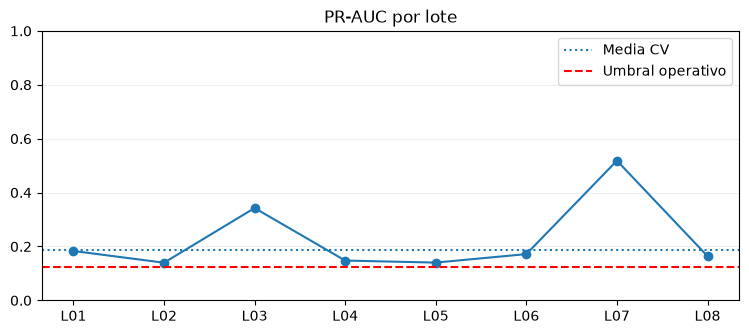

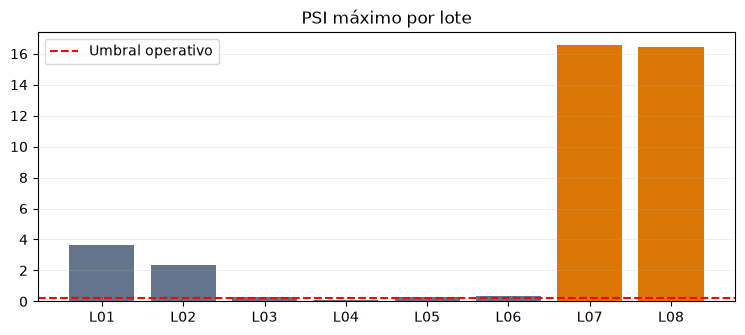

,simulacion_id,lote_id,feature,tipo,psi,prueba_estadistica,estadistico,p_valor,prueba_valida,pct_faltantes,pct_fuera_rango,categorias_no_vistas,pct_categorias_no_vistas
78,SIM_2025_V1,L07,friccion_previa,numerica,16.579669,KS,0.969038,9.143466e-76,True,0.0,3.389831,0,0.0
79,SIM_2025_V1,L07,inasistencias_previas,numerica,15.369529,KS,0.933054,1.707417e-62,True,0.0,0.000000,0,0.0
80,SIM_2025_V1,L07,cancelaciones_previas,numerica,14.598471,KS,0.902929,4.363614e-55,True,0.0,1.694915,0,0.0
81,SIM_2025_V1,L07,edad_en_atencion,numerica,0.186291,KS,0.128431,2.853603e-01,True,0.0,3.389831,0,0.0
82,SIM_2025_V1,L07,ritmo_dias_por_sesion,numerica,0.148179,KS,0.116786,3.955903e-01,True,0.0,0.000000,0,0.0
83,SIM_2025_V1,L07,progreso_plan,numerica,0.080750,KS,0.076136,8.742370e-01,True,0.0,0.000000,0,0.0
84,SIM_2025_V1,L07,codigo_procedimiento,categorica,0.079041,Chi2,4.436030,4.884878e-01,True,0.0,0.000000,0,0.0
85,SIM_2025_V1,L07,duracion_estimada_min,numerica,0.079041,KS,0.072037,9.109591e-01,True,0.0,0.000000,0,0.0
86,SIM_2025_V1,L07,odontologo_key,categorica,0.076607,Chi2,3.590676,4.642254e-01,True,0.0,0.000000,0,0.0
87,SIM_2025_V1,L07,sesiones_planificadas,numerica,0.062791,KS,0.109155,4.794577e-01,True,0.0,0.000000,0,0.0


,lote_id,pct_faltantes_max,pct_fuera_rango_max,pct_categorias_no_vistas_max,volumen_http,errores_4xx,errores_5xx,latencia_http_p95_ms
0,L01,0.0,8.333333,0.0,NaN,NaN,NaN,NaN
1,L02,0.0,0.000000,0.0,37.0,0.0,0.0,4037.292960
2,L03,0.0,0.000000,0.0,53.0,0.0,0.0,4546.613179
3,L04,0.0,0.000000,0.0,61.0,0.0,0.0,3802.229917
4,L05,0.0,0.000000,0.0,54.0,0.0,0.0,3758.259685
5,L06,0.0,0.000000,0.0,68.0,0.0,0.0,4096.078447
6,L07,0.0,3.389831,0.0,59.0,0.0,0.0,4111.295891
7,L08,0.0,3.174603,0.0,63.0,0.0,0.0,4132.117899


,simulacion_id,lote_id,fase,codigo,fecha_simulada,metrica,valor_observado,umbral,ventana,severidad,destinatario,accion,fecha_registro
0,SIM_2025_V1,L01,inmediato,psi,2025-08-03,PSI de ritmo_dias_por_sesion,3.623896,>= 0.25,1 lote,Alta,Equipo de Datos / MLOps,Revisar distribución y calidad; esperar target...,2026-11-23 21:50:35.357-08:00
1,SIM_2025_V1,L01,inmediato,fuera_rango,2025-08-03,Porcentaje fuera del rango de entrenamiento,8.333333,> 5.0%,1 lote,Media,Equipo de Datos / MLOps,Auditar entradas y fuente de datos.,2026-11-23 21:50:35.942-08:00
2,SIM_2025_V1,L02,inmediato,psi,2025-08-10,PSI de edad_en_atencion,2.331177,>= 0.25,1 lote,Alta,Equipo de Datos / MLOps,Revisar distribución y calidad; esperar target...,2026-11-23 23:00:47.035-08:00
3,SIM_2025_V1,L02,inmediato,latencia,2025-08-10,Latencia HTTP p95 (ms),4037.292960,> 250 ms,1 lote,Media,Equipo de Plataforma / API,Revisar latencia de extremo a extremo y persis...,2026-11-23 23:00:47.561-08:00
4,SIM_2025_V1,L03,inmediato,psi,2025-08-17,PSI de friccion_previa,0.309033,>= 0.25,1 lote,Alta,Equipo de Datos / MLOps,Revisar distribución y calidad; esperar target...,2026-11-23 23:01:11.239-08:00
5,SIM_2025_V1,L03,inmediato,latencia,2025-08-17,Latencia HTTP p95 (ms),4546.613179,> 250 ms,1 lote,Media,Equipo de Plataforma / API,Revisar latencia de extremo a extremo y persis...,2026-11-23 23:01:12.362-08:00
6,SIM_2025_V1,L04,inmediato,psi,2025-08-24,PSI de duracion_estimada_min,0.102152,>= 0.1,1 lote,Media,Equipo de Datos / MLOps,Revisar distribución y calidad; esperar target...,2026-11-23 23:01:33.056-08:00
7,SIM_2025_V1,L04,inmediato,latencia,2025-08-24,Latencia HTTP p95 (ms),3802.229917,> 250 ms,1 lote,Media,Equipo de Plataforma / API,Revisar latencia de extremo a extremo y persis...,2026-11-23 23:01:33.936-08:00
8,SIM_2025_V1,L05,inmediato,psi,2025-08-31,PSI de friccion_previa,0.309250,>= 0.25,1 lote,Alta,Equipo de Datos / MLOps,Revisar distribución y calidad; esperar target...,2026-11-23 23:01:50.211-08:00
9,SIM_2025_V1,L05,inmediato,latencia,2025-08-31,Latencia HTTP p95 (ms),3758.259685,> 250 ms,1 lote,Media,Equipo de Plataforma / API,Revisar latencia de extremo a extremo y persis...,2026-11-23 23:01:51.231-08:00


In [2]:
for df,col,titulo,umbral in [(mon,'pr_auc','PR-AUC por lote',umbral_pr),(inm,'psi_max','PSI máximo por lote',.25)]:
    fig,ax=plt.subplots(figsize=(9,3.5))
    if col=='pr_auc':
        ax.plot(df.lote_id,df[col],marker='o'); ax.set_ylim(0,1)
        ax.axhline(media,linestyle=':',label='Media CV')
    else:
        ax.bar(df.lote_id,df[col],color=['#d97706' if x else '#64748b' for x in df.deriva_inducida])
    ax.axhline(umbral,color='red',linestyle='--',label='Umbral operativo')
    ax.set_title(titulo); ax.legend(); ax.grid(axis='y',alpha=.2); plt.show()
display(deriva[deriva.lote_id.isin(['L07','L08'])].sort_values(['lote_id','psi'],ascending=[True,False]))
display(inm[['lote_id','pct_faltantes_max','pct_fuera_rango_max','pct_categorias_no_vistas_max','volumen_http','errores_4xx','errores_5xx','latencia_http_p95_ms']])
display(alertas)


In [3]:
diagnostico = mon[['lote_id','pr_auc']].merge(inm[['lote_id','psi_max','deriva_inducida']],on='lote_id')
def interpretar(r):
    if pd.isna(r.pr_auc) or pd.isna(r.psi_max): return 'Evidencia insuficiente'
    if r.psi_max>=.25: return 'Deriva y deterioro' if r.pr_auc<umbral_pr else 'Deriva sin deterioro observado'
    return 'Deterioro sin deriva detectada' if r.pr_auc<umbral_pr else 'Sin alerta alta de deriva ni deterioro'
diagnostico['diagnostico']=diagnostico.apply(interpretar,axis=1)
display(diagnostico)
print('Alertas PSI altas en lotes no alterados:', ((diagnostico.psi_max>=.25)&~diagnostico.deriva_inducida).sum())

,lote_id,pr_auc,psi_max,deriva_inducida,diagnostico
0,L01,0.183333,3.623896,False,Deriva sin deterioro observado
1,L02,0.139808,2.331177,False,Deriva sin deterioro observado
2,L03,0.342671,0.309033,False,Deriva sin deterioro observado
3,L04,0.147778,0.102152,False,Sin alerta alta de deriva ni deterioro
4,L05,0.140276,0.309250,False,Deriva sin deterioro observado
5,L06,0.171771,0.325904,False,Deriva sin deterioro observado
6,L07,0.518482,16.579669,True,Deriva sin deterioro observado
7,L08,0.164138,16.417947,True,Deriva sin deterioro observado


Alertas PSI altas en lotes no alterados: 5


L07 y L08 muestran cambios artificiales claros, sin caída observada por debajo del umbral PR-AUC. Cinco lotes no alterados superan también el PSI alto; no deben etiquetarse automáticamente como falsos positivos, pues puede haber variación natural. L01 tiene solo 12 observaciones. El p95 HTTP excede el umbral de 250 ms en los lotes con telemetría disponible; incluye persistencia y transporte, no solo inferencia. No se modifica retrospectivamente el umbral.

## 2. Impacto económico
Costo hipotético de errores = 120 × FN + 3 × FP. No representa ahorro observado ni costo total de intervención. Se incluyen escenarios alterados y se separan para evitar confundirlos con producción original.

,lote_id,costo_modelo_usd,costo_regla_1_sesion_usd,costo_llamar_todos_usd,costo_no_hacer_nada_usd
0,L01,30.0,9.0,30.0,240.0
1,L02,99.0,408.0,99.0,480.0
2,L03,129.0,561.0,129.0,1200.0
3,L04,168.0,456.0,171.0,480.0
4,L05,144.0,195.0,144.0,720.0
5,L06,177.0,567.0,177.0,1080.0
6,L07,129.0,192.0,141.0,1440.0
7,L08,156.0,924.0,159.0,1200.0


,total,sin_deriva_inducida,con_deriva_inducida
costo_modelo_usd,1032.0,747.0,285.0
costo_regla_1_sesion_usd,3312.0,2196.0,1116.0
costo_llamar_todos_usd,1050.0,750.0,300.0
costo_no_hacer_nada_usd,6840.0,4200.0,2640.0


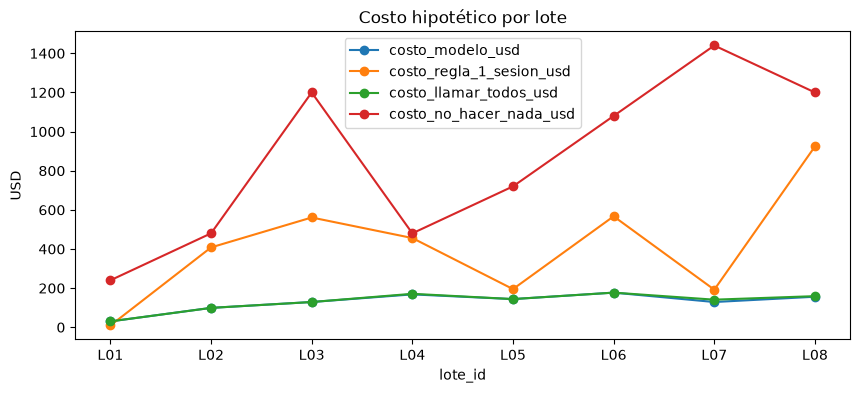

TP=57, FP=344, FN=0, TN=6; precisión=14.21%; recall=100.00%; contacto=98.53%


In [4]:
costos=['costo_modelo_usd','costo_regla_1_sesion_usd','costo_llamar_todos_usd','costo_no_hacer_nada_usd']
display(mon[['lote_id',*costos]])
display(pd.DataFrame({'total':mon[costos].sum(),'sin_deriva_inducida':mon.loc[~mon.deriva_inducida,costos].sum(),'con_deriva_inducida':mon.loc[mon.deriva_inducida,costos].sum()}))
mon.set_index('lote_id')[costos].plot(marker='o',figsize=(10,4),ylabel='USD',title='Costo hipotético por lote'); plt.show()
tp,fp,fn,tn=mon[['tp','fp','fn','tn']].sum()
print(f'TP={tp}, FP={fp}, FN={fn}, TN={tn}; precisión={tp/(tp+fp):.2%}; recall={tp/(tp+fn):.2%}; contacto={(tp+fp)/(tp+fp+fn+tn):.2%}')

## 3. Equidad y errores por subgrupo
Se reconstruyen etiquetas únicamente de sesiones ya evaluadas con Gold congelado y el horizonte individual. Se analizan edad y código del procedimiento con predicciones históricas, no inferencias nuevas. Las tasas son por sesión, no por paciente único; grupos pequeños y clases ausentes limitan interpretación.

In [5]:
casos = consulta(f"""
SELECT p.ID_PREDICCION,p.SESION_KEY,p.LOTE_ID,p.PROBABILIDAD,p.DECISION,
 p.DERIVA_INDUCIDA,o.EDAD_EN_ATENCION,o.CODIGO_PROCEDIMIENTO,
 IFF(COUNT(g.SESION_KEY)>0,0,1) AS ABANDONO_60D
FROM {SCHEMA}.PREDICCIONES p
JOIN {SCHEMA}.SNAP_SIM_2025_V1_OBT o ON p.SESION_KEY=o.SESION_KEY AND p.PLAN_TRATAMIENTO_ID=o.PLAN_TRATAMIENTO_ID AND p.PACIENTE_KEY=o.PACIENTE_KEY
JOIN {SCHEMA}.LOTES_PRODUCCION l ON p.SIMULACION_ID=l.SIMULACION_ID AND p.LOTE_ID=l.LOTE_ID
LEFT JOIN {SCHEMA}.SNAP_SIM_2025_V1_GOLD g ON g.PLAN_TRATAMIENTO_ID=o.PLAN_TRATAMIENTO_ID
 AND g.INDICADOR_COMPLETADA=1 AND g.FECHA_REALIZADA>o.FECHA_REALIZADA
 AND g.FECHA_REALIZADA<=p.FECHA_MADURACION AND g.FECHA_REALIZADA<=l.FECHA_EVALUACION_SIMULADA
WHERE p.SIMULACION_ID='{SIM}' AND p.LOTE_ID BETWEEN 'L01' AND 'L08'
 AND l.ESTADO='evaluado' AND p.FECHA_MADURACION<=l.FECHA_EVALUACION_SIMULADA
GROUP BY p.ID_PREDICCION,p.SESION_KEY,p.LOTE_ID,p.PROBABILIDAD,p.DECISION,
 p.DERIVA_INDUCIDA,o.EDAD_EN_ATENCION,o.CODIGO_PROCEDIMIENTO
""")
assert len(casos)==407 and casos.id_prediccion.is_unique
assert casos.abandono_60d.sum()==mon.abandonos.sum()
casos['grupo_edad']=pd.cut(casos.edad_en_atencion.astype(float),[-np.inf,18,40,60,np.inf],right=False,labels=['<18','18–39','40–59','60+'])
def resumen_grupo(df,col):
    filas=[]
    for grupo,g in df.groupby(col,observed=True,dropna=False):
        y=g.abandono_60d.astype(int); d=g.decision.eq('contactar'); pos=y.eq(1); neg=~pos
        tp=int((d&pos).sum()); fp=int((d&neg).sum()); fn=int((~d&pos).sum())
        filas.append(dict(variable=col,grupo=str(grupo),n=len(g),positivos=int(pos.sum()),tasa_contactar=d.mean(),recall=tp/pos.sum() if pos.any() else np.nan,precision=tp/d.sum() if d.any() else np.nan,fpr=fp/neg.sum() if neg.any() else np.nan,pr_auc=average_precision_score(y,g.probabilidad) if y.nunique()==2 else np.nan,fp=fp,fn=fn,muestra_pequena=len(g)<30 or pos.sum()<5))
    return pd.DataFrame(filas)
equidad=pd.concat([resumen_grupo(casos,c) for c in ['grupo_edad','codigo_procedimiento']],ignore_index=True)
display(equidad)
display(pd.concat([resumen_grupo(casos.loc[~casos.deriva_inducida],c) for c in ['grupo_edad','codigo_procedimiento']],ignore_index=True))

c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\snowflake\connector\connection\_connection.py:137: FutureWarning: enable_server_session_keep_alive_auto_detection was not set and defaults to True. In a future version, the default will change to None. Please provide an explicit value: True = check for running async queries before logout (queries are preserved); False/None = always send logout on close (async queries may be terminated by server). Logout behavior can also be overridden with server_session_keep_alive. See the connection parameter docs for more info.
  options = self.config.to_proto_options(


,variable,grupo,n,positivos,tasa_contactar,recall,precision,fpr,pr_auc,fp,fn,muestra_pequena
0,grupo_edad,<18,36,9,1.000000,1.0,0.250000,1.000000,0.318887,27,0,False
1,grupo_edad,18–39,127,14,0.968504,1.0,0.113821,0.964602,0.090584,109,0,False
2,grupo_edad,40–59,107,15,0.990654,1.0,0.141509,0.989130,0.223756,91,0,False
3,grupo_edad,60+,137,19,0.992701,1.0,0.139706,0.991525,0.149759,117,0,False
4,codigo_procedimiento,CROWN,85,14,1.000000,1.0,0.164706,1.000000,0.155204,71,0,False
5,codigo_procedimiento,EXTRACT,28,5,1.000000,1.0,0.178571,1.000000,0.364183,23,0,True
6,codigo_procedimiento,FILL1,29,7,1.000000,1.0,0.241379,1.000000,0.245999,22,0,True
7,codigo_procedimiento,FILL2,61,4,1.000000,1.0,0.065574,1.000000,0.054388,57,0,True
8,codigo_procedimiento,ROOT,108,13,0.972222,1.0,0.123810,0.968421,0.152689,92,0,False
9,codigo_procedimiento,WHITEN,96,14,0.968750,1.0,0.150538,0.963415,0.236956,79,0,False


,variable,grupo,n,positivos,tasa_contactar,recall,precision,fpr,pr_auc,fp,fn,muestra_pequena
0,grupo_edad,<18,25,7,1.000000,1.0,0.280000,1.000000,0.369604,18,0,True
1,grupo_edad,18–39,90,7,1.000000,1.0,0.077778,1.000000,0.070408,83,0,False
2,grupo_edad,40–59,69,9,1.000000,1.0,0.130435,1.000000,0.256543,60,0,False
3,grupo_edad,60+,101,12,0.990099,1.0,0.120000,0.988764,0.152402,88,0,False
4,codigo_procedimiento,CROWN,62,8,1.000000,1.0,0.129032,1.000000,0.126435,54,0,False
5,codigo_procedimiento,EXTRACT,19,3,1.000000,1.0,0.157895,1.000000,0.477273,16,0,True
6,codigo_procedimiento,FILL1,22,5,1.000000,1.0,0.227273,1.000000,0.231520,17,0,True
7,codigo_procedimiento,FILL2,41,1,1.000000,1.0,0.024390,1.000000,0.040000,40,0,True
8,codigo_procedimiento,ROOT,69,7,1.000000,1.0,0.101449,1.000000,0.173192,62,0,False
9,codigo_procedimiento,WHITEN,72,11,0.986111,1.0,0.154930,0.983607,0.258599,60,0,False


Los falsos positivos consumen tiempo de recepción y pueden generar contactos innecesarios; los falsos negativos omiten seguimiento preventivo y pueden afectar continuidad. La tasa casi universal de contacto limita el valor de priorización. La recepción revisa cada sugerencia; no se restringe atención ni se automatizan decisiones clínicas. No se infiere equidad clínica a partir de grupos sintéticos o con pocos casos.

### Condiciones propuestas de retirada
| Indicador | Umbral y ventana | Responsable / acción |
|---|---|---|
| Fallo de carga | Una detección de modelo no disponible | MLOps: activar respaldo automático y restaurar servicio |
| Recall de abandonos | <80% en dos lotes maduros consecutivos con al menos 5 positivos cada uno | Responsable clínico y MLOps: activar respaldo y revisar errores |
| Costo de errores | Superior a contactar a todos en dos lotes maduros consecutivos | Administración: suspender recomendación ML y revisar política |
| Fallos HTTP 5xx | >5% en dos lotes consecutivos con al menos 30 solicitudes | Plataforma: retirar temporalmente el modelo del circuito y revisar servicio |

Estas son políticas propuestas de supervisión humana, no todas están automatizadas. El interruptor protegido `/admin/respaldo` y el respaldo automático ya fueron probados. La alerta PSI sola motiva investigación, no retirada ni reentrenamiento automático.

## 4. Reentrenamiento por calendario y decisión humana
Evaluación retrospectiva en L14 original, excluido del entrenamiento del challenger, pero ya perteneciente al hold-out de PSet03. No es una validación externa independiente. Se registra la decisión sin volver a entrenar.

In [6]:
runs=mlflow.search_runs(search_all_experiments=True)
reent=runs.loc[runs['tags.fase'].eq('reentrenamiento')].copy()
assert not reent.empty
cols=['run_id','params.lote_evaluacion','params.n_filas_entrenamiento','params.n_filas_evaluacion','tags.version_candidata','metrics.pr_auc_champion_eval','metrics.pr_auc_challenger_eval','metrics.costo_errores_usd_champion_eval','metrics.costo_errores_usd_challenger_eval','tags.decision_humana','tags.estado_promocion','tags.motivo_decision']
display(reent[cols])
activo=client.get_model_version_by_alias('oralsolutions-modelo','champion')
print('Champion actual:',activo.version,activo.run_id)

,run_id,params.lote_evaluacion,params.n_filas_entrenamiento,params.n_filas_evaluacion,tags.version_candidata,metrics.pr_auc_champion_eval,metrics.pr_auc_challenger_eval,metrics.costo_errores_usd_champion_eval,metrics.costo_errores_usd_challenger_eval,tags.decision_humana,tags.estado_promocion,tags.motivo_decision
0,7a1b8f68e3f041ecaeed49b117418d52,L14,1745,81,3,0.327545,0.378327,195.0,198.0,rechazar,rechazado,"Se rechaza la promoción del challenger porque,..."


Champion actual: 1 c90a1c37aef940278afc025b1d22dc6b


El challenger mejora PR-AUC de 0,327545 a 0,378327, pero aumenta el costo de 195 a 198 USD. Se rechazó y se conservó v1. No hay impacto económico posterior atribuible a un modelo promovido; el resultado es una comparación contrafactual de errores en L14. El modelo no ha demostrado ventaja económica robusta frente a contactar a todos ni mejora causal de continuidad.

## 5. Exportación de resultados

In [7]:
for nombre,df in [('monitoreo',mon),('monitoreo_inmediato',inm),('deriva_features',deriva),('alertas',alertas),('equidad',equidad),('corridas',runs),('reentrenamientos',reent)]:
    df.to_csv(DOCS/f'{nombre}.csv',index=False)
print('Exportación completada.')

Exportación completada.


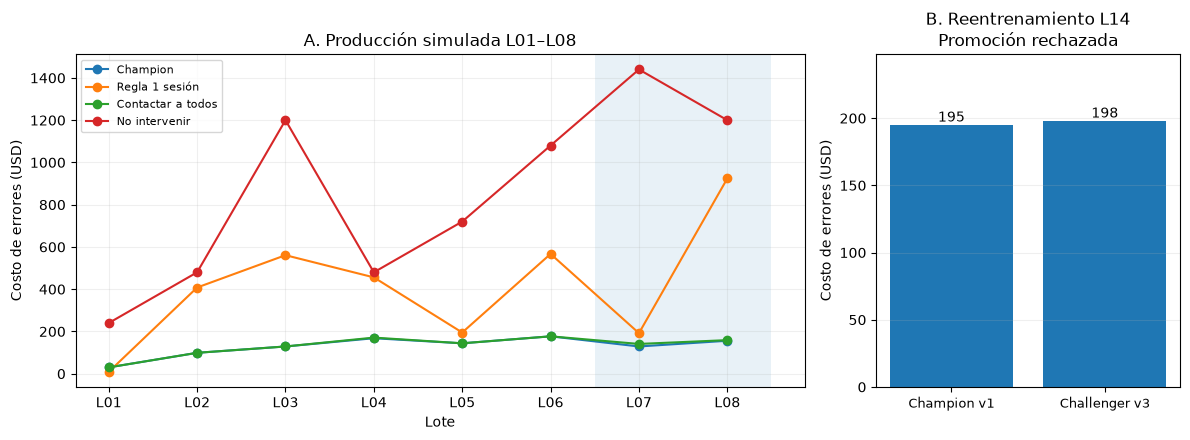

In [2]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Localizar la raíz del proyecto.
ROOT = Path.cwd()

if not (ROOT / "docs").exists():
    ROOT = ROOT.parent

DOCS = ROOT / "docs"

# Evidencias existentes, sin nuevas inferencias.
df = pd.read_csv(DOCS / "monitoreo.csv")
df = df.sort_values("lote_id")

df = df[df["lote_id"].isin(
    [f"L{i:02d}" for i in range(1, 9)]
)]

reent = pd.read_csv(DOCS / "reentrenamientos.csv")

reent = reent.loc[
    reent["params.lote_evaluacion"].eq("L14")
].iloc[-1]

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(12, 4.5),
    gridspec_kw={"width_ratios": [2.4, 1]}
)

# Panel A: producción simulada.
estrategias = {
    "costo_modelo_usd": "Champion",
    "costo_regla_1_sesion_usd": "Regla 1 sesión",
    "costo_llamar_todos_usd": "Contactar a todos",
    "costo_no_hacer_nada_usd": "No intervenir",
}

for columna, etiqueta in estrategias.items():
    ax1.plot(
        df["lote_id"],
        df[columna],
        marker="o",
        label=etiqueta
    )

ax1.axvspan(5.5, 7.5, alpha=0.10)

ax1.set_title("A. Producción simulada L01–L08")
ax1.set_xlabel("Lote")
ax1.set_ylabel("Costo de errores (USD)")
ax1.legend(fontsize=8)
ax1.grid(alpha=0.2)

# Panel B: reentrenamiento.
costos = [
    reent["metrics.costo_errores_usd_champion_eval"],
    reent["metrics.costo_errores_usd_challenger_eval"]
]

barras = ax2.bar(
    ["Champion v1", "Challenger v3"],
    costos
)

ax2.bar_label(barras, fmt="%.0f")
ax2.set_ylim(0, max(costos) * 1.25)
ax2.set_title("B. Reentrenamiento L14\nPromoción rechazada")
ax2.set_ylabel("Costo de errores (USD)")
ax2.tick_params(axis="x", labelsize=9)
ax2.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()